# Xenium + Visium example

## Loading the data

In [ ]:
# %load_ext jupyter_black

In [2]:
import spatialdata as sd
import spatialdata_plot
import warnings
import matplotlib.pyplot as plt
import numpy as np
from shapely import Polygon
from geopandas import GeoDataFrame

from napari_spatialdata import Interactive

warnings.filterwarnings("ignore")

In [3]:
xenium_sdata = sd.read_zarr("spatialdata-sandbox/xenium_rep1_io/data.zarr")
xenium_sdata

INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         


SpatialData object with:
├── Images
│     ├── 'morphology_focus': MultiscaleSpatialImage[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
│     └── 'morphology_mip': MultiscaleSpatialImage[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
├── Points
│     ├── 'new_transcripts': DataFrame with shape: (42638083, 7) (2D points)
│     ├── 'transcripts': DataFrame with shape: (42638083, 8) (3D points)
│     └── 'xenium_landmarks': DataFrame with shape: (3, 2) (2D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (167780, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (167780, 2) (2D shapes)
│     ├── 'grid': GeoDataFrame shape: (10300356, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (167780, 1) (2D shapes)
└── Table
      └── AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_code

In [4]:
visium_sdata = sd.read_zarr("spatialdata-sandbox/visium_associated_xenium_io/data.zarr")
visium_sdata

SpatialData object with:
├── Images
│     ├── 'CytAssist_FFPE_Human_Breast_Cancer_full_image': MultiscaleSpatialImage[cyx] (3, 21571, 19505), (3, 10785, 9752), (3, 5392, 4876), (3, 2696, 2438), (3, 1348, 1219)
│     ├── 'CytAssist_FFPE_Human_Breast_Cancer_hires_image': SpatialImage[cyx] (3, 2000, 1809)
│     └── 'CytAssist_FFPE_Human_Breast_Cancer_lowres_image': SpatialImage[cyx] (3, 600, 543)
├── Points
│     └── 'visium_landmarks': DataFrame with shape: (3, 2) (2D points)
├── Shapes
│     └── 'CytAssist_FFPE_Human_Breast_Cancer': GeoDataFrame shape: (4992, 2) (2D shapes)
└── Table
      └── AnnData object with n_obs × n_vars = 4992 × 18085
    obs: 'in_tissue', 'array_row', 'array_col', 'spot_id', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'spatialdata_attrs'
    obsm: 'spatial': AnnData (4992, 18085)
with coordinate systems:
▸ 'downscaled_hires', with elements:
        CytAssist_FFPE_Human_Breast_Cancer_hires_image (Images), CytAssist_FFPE_Human_Brea

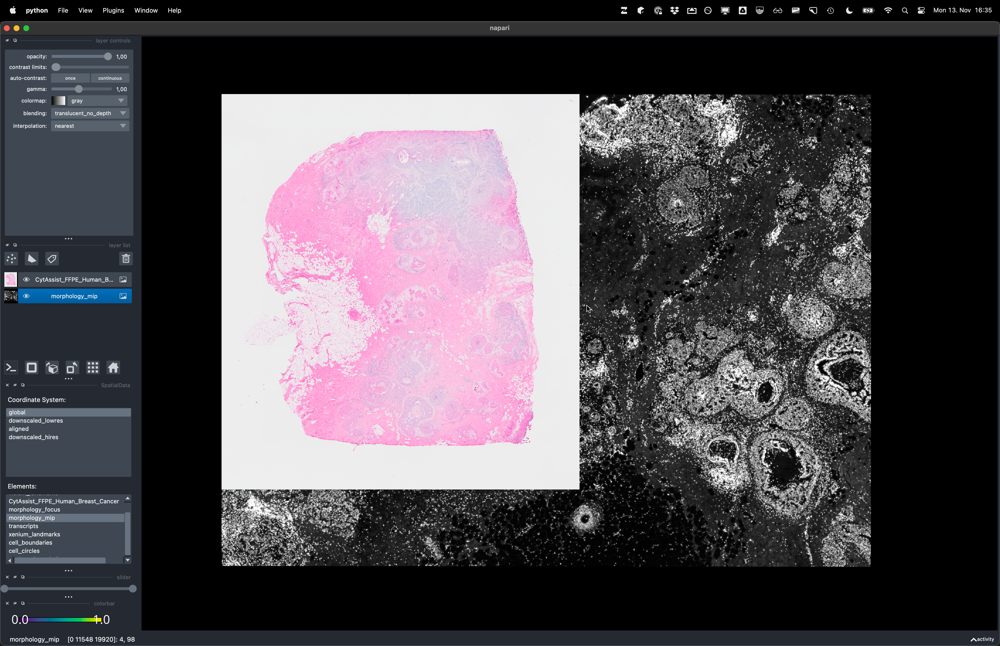

## Interactive landmark-based alignment

### Saving the landmarks

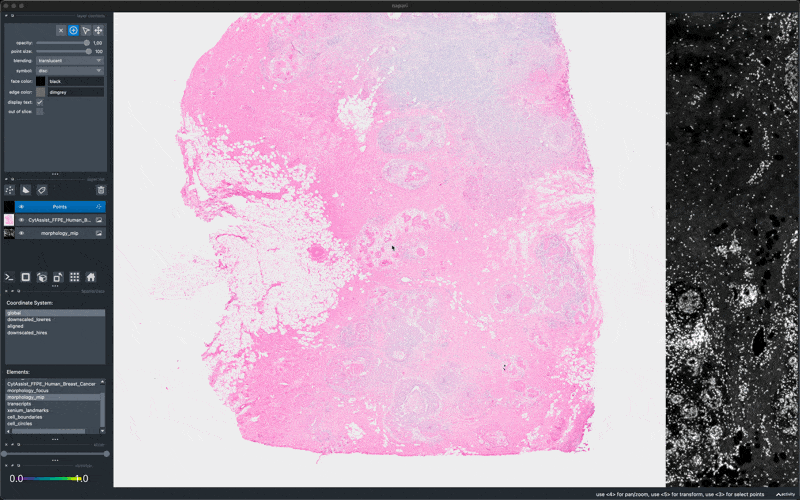

In [5]:
xenium_landmarks = sd.models.PointsModel.parse(
    np.array([[9438, 13933], [24847, 5948], [34082, 15234]])
)
visium_landmarks = sd.models.PointsModel.parse(
    np.array([[10566, 7895], [13951, 13574], [10660, 17323]])
)

xenium_sdata.points["xenium_landmarks"] = xenium_landmarks
visium_sdata.points["visium_landmarks"] = visium_landmarks

### Aligning the images

In [6]:
from spatialdata.transformations import (
    align_elements_using_landmarks,
    get_transformation_between_landmarks,
)

affine = get_transformation_between_landmarks(
    references_coords=xenium_sdata["xenium_landmarks"],
    moving_coords=visium_sdata["visium_landmarks"],
)
affine

Affine (x, y -> x, y)
    [ 1.63919514e-01  2.61564533e+00 -1.29551035e+04]
    [-2.61564533e+00  1.63919514e-01  4.02555967e+04]
    [0. 0. 1.]

In [7]:
_ = align_elements_using_landmarks(
    references_coords=xenium_sdata["xenium_landmarks"],
    moving_coords=visium_sdata["visium_landmarks"],
    reference_element=xenium_sdata["morphology_mip"],
    moving_element=visium_sdata["CytAssist_FFPE_Human_Breast_Cancer_full_image"],
    reference_coordinate_system="global",
    moving_coordinate_system="global",
    new_coordinate_system="aligned",
)

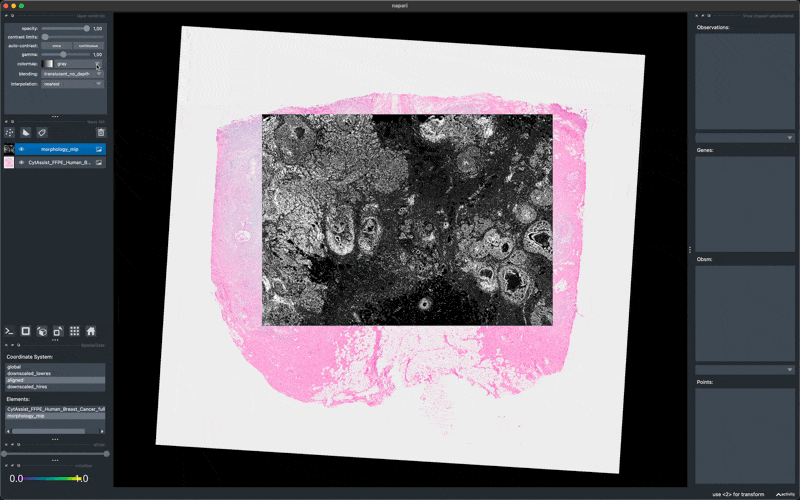

### Align the rest of the elements

In [8]:
from spatialdata import SpatialData
from spatialdata.transformations import (
    BaseTransformation,
    Sequence,
    Identity,
    get_transformation,
    set_transformation,
)


def postpone_transformation(
    sdata: SpatialData,
    transformation: BaseTransformation,
    source_coordinate_system: str,
    target_coordinate_system: str,
):
    for element_type, element_name, element in sdata._gen_elements():
        old_transformations = get_transformation(element, get_all=True)
        if source_coordinate_system in old_transformations:
            old_transformation = old_transformations[source_coordinate_system]
            sequence = Sequence([old_transformation, transformation])
            set_transformation(element, sequence, target_coordinate_system)


postpone_transformation(
    sdata=visium_sdata,
    transformation=affine,
    source_coordinate_system="global",
    target_coordinate_system="aligned",
)
postpone_transformation(
    sdata=xenium_sdata,
    transformation=Identity(),
    source_coordinate_system="global",
    target_coordinate_system="aligned",
)

## Saving regions of interests (ROIs)

In [9]:
# saving the ROI to make the notebook reproducible
# fmt: off
x = np.array([766, 767, 773, 787, 806, 813, 830, 848, 862, 863, 867, 887, 907, 914, 918, 930, 947, 964, 968, 985, 982, 
              966, 976, 995, 1024, 1058, 1071, 1073, 1075, 1092, 1113, 1113, 1108, 1100, 1096, 1089, 1079, 1059, 1038, 
              1018, 993, 972, 946, 926, 905, 880, 862, 843, 825, 810, 802, 786, 778, 774, 771, 768, 766])
# fmt: on

# fmt: off
y = np.array([1460, 1437, 1415, 1390, 1397, 1415, 1432, 1447, 1467, 1517, 1538, 1546, 1554, 1586, 1609, 1628, 1638, 1631, 1604, 
          1593, 1573, 1564, 1548, 1539, 1537, 1534, 1521, 1491, 1472, 1462, 1463, 1536, 1556, 1589, 1617, 1638, 1662, 1686, 
          1702, 1712, 1721, 1729, 1725, 1717, 1709, 1702, 1690, 1675, 1656, 1641, 1623, 1592, 1571, 1550, 1525, 1504, 1470]) 
# fmt: on

polygon = Polygon(zip(x * 10, y * 10))
visium_sdata["Shapes"] = sd.models.ShapesModel.parse(
    GeoDataFrame({"geometry": [polygon]})
)

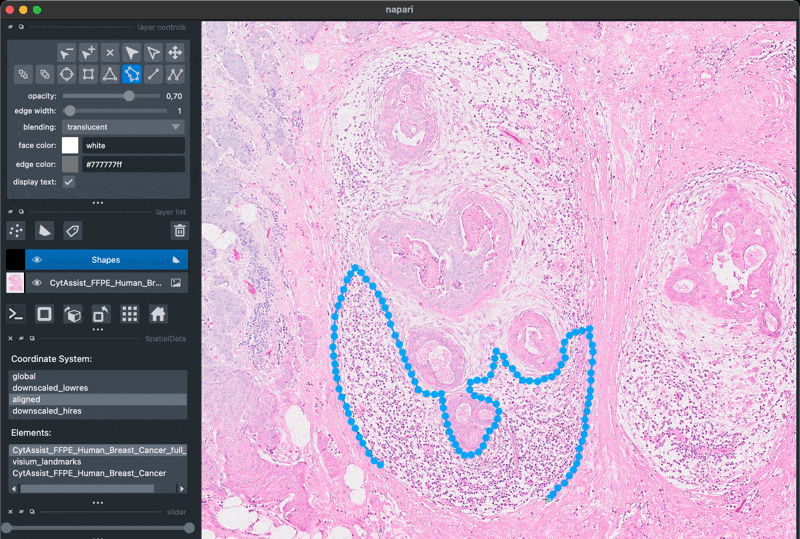

In [10]:
if "grid" in xenium_sdata.shapes:
    del xenium_sdata.shapes["grid"]

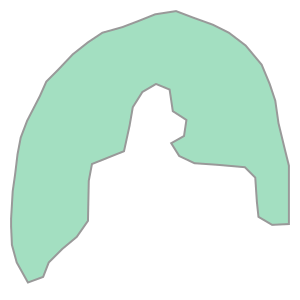

In [11]:
visium_sdata["Shapes"].iloc[0].geometry

In [12]:
# we won't use this, so let's speed up the query operation
if "nucleus_boundaries" in xenium_sdata.shapes:
    del xenium_sdata.shapes["nucleus_boundaries"]

In [13]:
%%time
query_result = sd.polygon_query(
    xenium_sdata, visium_sdata["Shapes"].iloc[0].geometry, "aligned", points=False
)

CPU times: user 57.6 s, sys: 20.1 s, total: 1min 17s
Wall time: 1min 16s


In [14]:
query_result

SpatialData object with:
├── Images
│     ├── 'morphology_focus': MultiscaleSpatialImage[cyx] (1, 3390, 3470), (1, 1695, 1735), (1, 847, 868), (1, 424, 434), (1, 212, 216)
│     └── 'morphology_mip': MultiscaleSpatialImage[cyx] (1, 3390, 3470), (1, 1695, 1735), (1, 847, 868), (1, 424, 434), (1, 212, 216)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (2933, 1) (2D shapes)
│     └── 'cell_circles': GeoDataFrame shape: (2866, 2) (2D shapes)
└── Table
      └── AnnData object with n_obs × n_vars = 2866 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial': AnnData (2866, 313)
with coordinate systems:
▸ 'aligned', with elements:
        morphology_focus (Images), morphology_mip (Images), transcripts (Po

In [15]:
from spatialdata._utils import multiscale_spatial_image_from_data_tree
from dask.array.core import Array as DaskArray
from multiscale_spatial_image import MultiscaleSpatialImage


def rechunk(msi: MultiscaleSpatialImage) -> DaskArray:
    for scale in msi.keys():
        msi[scale]["image"].data = msi[scale]["image"].data.rechunk()


rechunk(query_result["morphology_focus"])
rechunk(query_result["morphology_mip"])

In [16]:
query_result.write("query_result.zarr", overwrite=True)

,geometry
0,"POLYGON ((1928.166 9124.230, 1928.166 9151.215..."
1,"POLYGON ((8109.926 14163.968, 8109.926 14173.7..."
2,"POLYGON ((32042.805 22387.401, 32026.302 22436..."
3,"POLYGON ((27504.676 20232.314, 27514.049 20237..."


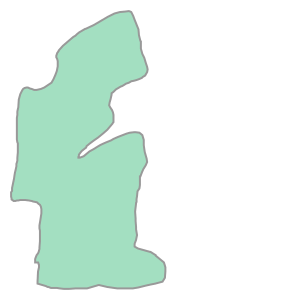

In [17]:
rois = sd.read_zarr("rois.zarr")
display(rois["rois"])
display(rois["rois"].geometry.iloc[0])

In [18]:
def remove_coordinate_system(
    sdata: SpatialData,
    coordinate_system: str,
):
    for element_type, element_name, element in sdata._gen_elements():
        if coordinate_system in get_transformation(element, get_all=True):
            sd.transformations.remove_transformation(element, coordinate_system)

In [19]:
remove_coordinate_system(xenium_sdata, "global")
rois.rename_coordinate_systems({"global": "aligned"})

INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Co

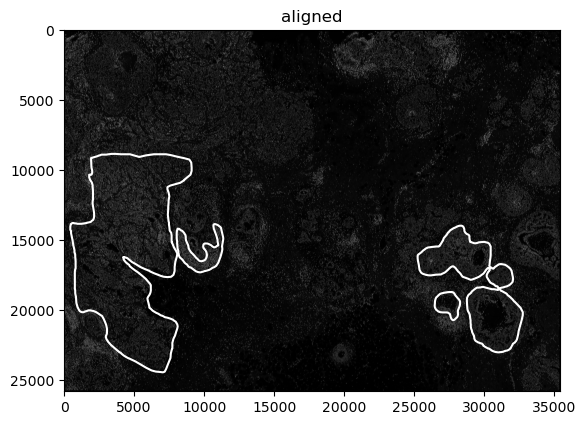

In [20]:
ax = plt.gca()
xenium_sdata.pl.render_images(cmap="gray").pl.show(ax=ax)
rois.pl.render_shapes(fill_alpha=0.0, outline_color="w", outline=True).pl.show(ax=ax)

## Query operations

In [21]:
# adding the cell-types from the paper (transferred from an external scRNA-Seq dataset)
sdata_paper = sd.read_zarr("spatialdata-sandbox/xenium_rep1_io/data_aligned.zarr")
cell_types = sdata_paper.table.obs["celltype_major"]
xenium_sdata.table.obs["celltype_major"] = cell_types

INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         
INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         


In [22]:
xenium_sdata.table.uns["spatialdata_attrs"]["region"] = ["cell_boundaries"]
xenium_sdata.table.obs["region"] = "cell_boundaries"
xenium_sdata.table.obs["region"] = xenium_sdata.table.obs["region"].astype("category")

In [23]:
xmin = 7622
xmax = 11630
ymin = 10772
ymax = 17453

small_sdata = xenium_sdata.query.bounding_box(
    min_coordinate=[xmin, ymin],
    max_coordinate=[xmax, ymax],
    target_coordinate_system="aligned",
    axes=["x", "y"],
    filter_table=True,
)

INFO     Feature key `feature_name`could be of type `pd.Categorical`. Consider casting it.                         


In [24]:
queried_sdata = sd.polygon_query(
    small_sdata,
    rois["rois"].geometry.iloc[1],
    target_coordinate_system="aligned",
    images=False,
    points=False,
)

In [25]:
from spatialdata.transformations import remove_transformation

for element in small_sdata._gen_elements_values():
    if "global" in get_transformation(element, get_all=True):
        remove_transformation(element, "global")

INFO     Using scale 'scale3' from multi-scale image 'morphology_focus'.                                           
INFO     Using scale 'scale3' from multi-scale image 'morphology_mip'.                                             
INFO     Using scale 'scale3' from multi-scale image 'morphology_focus'.                                           
INFO     Using scale 'scale3' from multi-scale image 'morphology_mip'.                                             


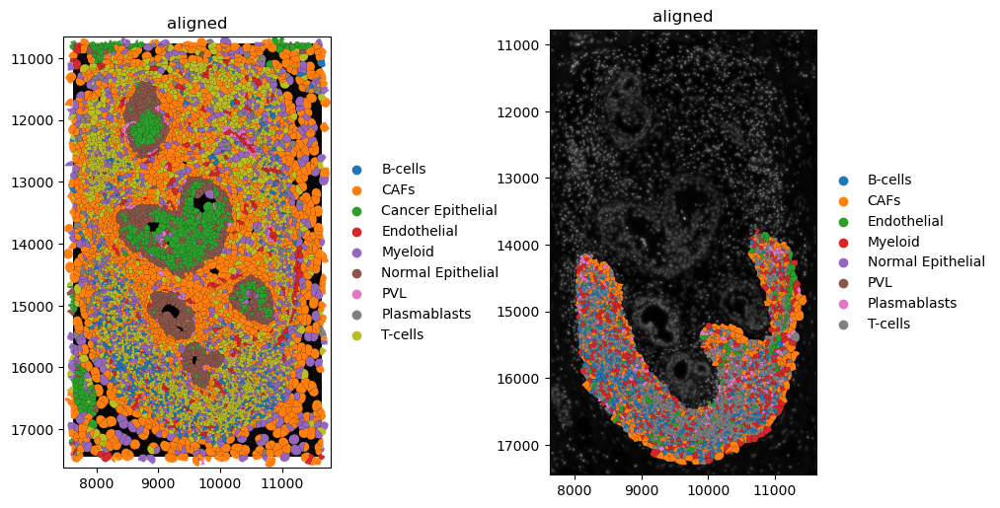

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 7))
small_sdata.pl.render_images(cmap="gray").pl.render_shapes(
    "cell_boundaries", color="celltype_major"
).pl.show(ax=axes[0])

small_sdata.pl.render_images(cmap="gray").pl.show(ax=axes[1])
queried_sdata.pl.render_shapes("cell_boundaries", color="celltype_major").pl.show(
    ax=axes[1]
)
plt.tight_layout()

## Aggregation of signals across modalities

In [27]:
xenium_sdata.table.uns["spatialdata_attrs"]["region"] = ["cell_boundaries"]
xenium_sdata.table.obs["region"] = "cell_boundaries"

In [28]:
cell_types_fractions = sd.aggregate(
    values_sdata=xenium_sdata,
    values="cell_boundaries",
    by_sdata=rois,
    by="rois",
    value_key="celltype_major",
    target_coordinate_system="aligned",
    fractions=True,
)
cell_types_fractions

SpatialData object with:
├── Shapes
│     └── 'rois': GeoDataFrame shape: (4, 1) (2D shapes)
└── Table
      └── AnnData object with n_obs × n_vars = 4 × 9
    obs: 'instance_id', 'region'
    uns: 'spatialdata_attrs': AnnData (4, 9)
with coordinate systems:
▸ 'aligned', with elements:
        rois (Shapes)

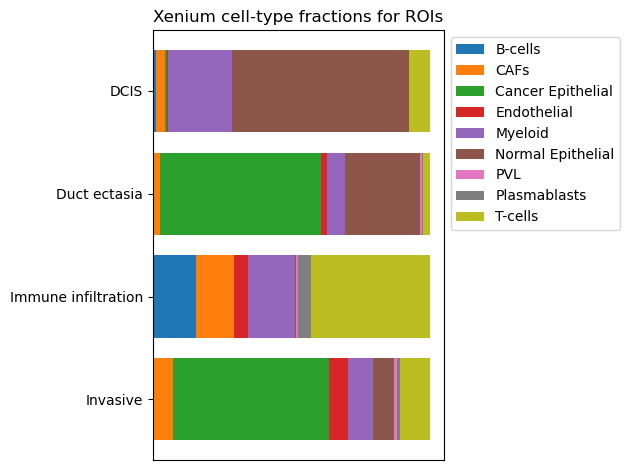

In [29]:
fig, ax = plt.subplots()

roi_names = ["Invasive", "Immune infiltration", "Duct ectasia", "DCIS"]
celltype_names = cell_types_fractions.table.var_names

data = cell_types_fractions.table.X.todense().A
data_normalized = data / data.sum(axis=1)[:, np.newaxis]
colors = plt.cm.tab10(np.linspace(0, 1, 10))

for i in range(data.shape[0]):
    left = 0
    for j, name in enumerate(celltype_names):
        ax.barh(
            i,
            data_normalized[i, j],
            left=left,
            color=colors[j],
            label=name if i == 0 else "",
        )
        left += data_normalized[i, j]

ax.set_yticks(np.arange(data.shape[0]))
ax.set_yticklabels([roi_names[i] for i in range(data.shape[0])])

ax.set_xticks([])

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))  # This removes duplicate labels/handles
ax.legend(by_label.values(), by_label.keys(), loc="upper left", bbox_to_anchor=(1, 1))

plt.title("Xenium cell-type fractions for ROIs")
plt.tight_layout()
plt.show()